# `vktorch`: PyTorch-Style Deep Learning on Vulkan GPU (MLP, CNN, & Causal Mini-GPT)

Train neural networks directly on AMD / Intel / NVIDIA / Steam Deck Vulkan GPUs via **`vktorch`** (built on `vknumpy` + `ggml-vulkan`, zero CUDA required):
1. **3-Spiral MLP Classifier** (`Linear` + `GELU` + `LayerNorm` + `AdamW` + `CosineAnnealingLR`) with live 2D decision boundary visualization.
2. **2D Convolutional Neural Network** (`Conv2d` + `MaxPool2d` + `Flatten` + `Linear`) trained on 4-class 12×12 synthetic vision patterns.
3. **Causal Mini-GPT Transformer** (`Embedding` + `TransformerBlock(is_causal=True)` + autoregressive text generation) trained end-to-end on Vulkan GPU!

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


3-Spiral MLP (4,803 params) trained 45 epochs in 33.42s | loss: 1.011 -> 0.000 | acc: 100.0%


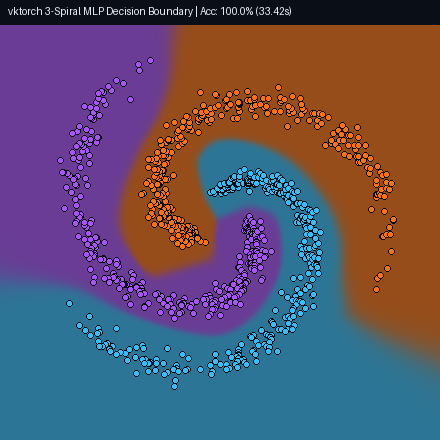

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vktorch as vt
from vktorch import F, nn, optim
from vktorch.data import DataLoader, TensorDataset

# 1. Generate 3-class intertwined 2D spirals (900 samples)
rng = np.random.default_rng(42)
n_per = 300
X_list, y_list = [], []
for k in range(3):
    r = np.linspace(0.15, 1.0, n_per)
    t = np.linspace(k * 4.0, (k + 1) * 4.0, n_per) + rng.normal(0.0, 0.20, n_per)
    X_list.append(np.column_stack([r * np.sin(t), r * np.cos(t)]))
    y_list.append(np.full(n_per, k, dtype=np.int32))
X_sp = np.vstack(X_list).astype(np.float32)
y_sp = np.concatenate(y_list)

mlp = nn.Sequential(
    nn.Linear(2, 64, seed=1), nn.GELU(), nn.LayerNorm(64),
    nn.Linear(64, 64, seed=2), nn.GELU(), nn.LayerNorm(64),
    nn.Linear(64, 3, seed=3),
)
opt = optim.AdamW(mlp.parameters(), lr=2.5e-2, weight_decay=1e-3)
sched = optim.CosineAnnealingLR(opt, T_max=45)
crit = nn.CrossEntropyLoss()
loader = DataLoader(TensorDataset(X_sp, y_sp), batch_size=90, shuffle=True, seed=42)

t0 = time.perf_counter()
loss_hist = []
for ep in range(45):
    ep_l = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = crit(mlp(xb), yb)
        loss.backward()
        opt.step()
        ep_l += loss.item()
    sched.step()
    loss_hist.append(ep_l / len(loader))
dt = time.perf_counter() - t0

with vt.no_grad():
    acc = float(np.mean(np.argmax(mlp(vt.Tensor(X_sp)).numpy(), axis=1) == y_sp))
print(f"3-Spiral MLP ({mlp.num_parameters():,} params) trained 45 epochs in {dt:.2f}s | loss: {loss_hist[0]:.3f} -> {loss_hist[-1]:.3f} | acc: {acc:.1%}")

# Render 2D decision boundary + data points
W, H = 440, 440
gx = np.linspace(-1.25, 1.25, W, dtype=np.float32)
gy = np.linspace(1.25, -1.25, H, dtype=np.float32)
xx, yy = np.meshgrid(gx, gy)
grid_pts = np.column_stack([xx.ravel(), yy.ravel()])
with vt.no_grad():
    probs = mlp(vt.Tensor(grid_pts)).softmax(axis=-1).numpy().reshape(H, W, 3)

pal = np.array([[56, 189, 248], [249, 115, 22], [168, 85, 247]], dtype=np.float32)
bg = np.clip((probs @ pal) * 0.55 + 14.0, 0, 255).astype(np.uint8)
im = Image.fromarray(bg, mode="RGB")
draw = ImageDraw.Draw(im)
for (px, py), cls in zip(X_sp, y_sp):
    ix = int((px + 1.25) / 2.5 * (W - 1))
    iy = int((1.25 - py) / 2.5 * (H - 1))
    c = tuple(int(v) for v in pal[cls])
    draw.ellipse([ix - 3, iy - 3, ix + 3, iy + 3], fill=c, outline=(10, 12, 18))
draw.rectangle([0, 0, W, 24], fill=(10, 14, 22))
draw.text((8, 5), f"vktorch 3-Spiral MLP Decision Boundary | Acc: {acc:.1%} ({dt:.2f}s)", fill=(235, 242, 250))
im

## 2. 2D Convolutional Neural Network (`Conv2d` + `MaxPool2d` + `Linear`)

Trains a 2D CNN on Vulkan GPU to classify 4 geometric vision patterns (`Horizontal`, `Vertical`, `Diagonal`, `Cross`) with random noise and jitter!

In [3]:
rng_c = np.random.default_rng(7)
n_img = 320
imgs = rng_c.normal(0.0, 0.22, (n_img, 1, 12, 12)).astype(np.float32)
lbls = np.zeros(n_img, dtype=np.int32)
class_names = ["Horiz", "Vert", "Diag", "Cross"]
for i in range(n_img):
    c = i % 4
    lbls[i] = c
    sh = int(rng_c.integers(-1, 2))
    if c == 0:
        imgs[i, 0, 5 + sh : 7 + sh, 1:11] += 1.4
    elif c == 1:
        imgs[i, 0, 1:11, 5 + sh : 7 + sh] += 1.4
    elif c == 2:
        for k in range(1, 11):
            imgs[i, 0, k, min(11, max(0, k + sh))] += 1.4
    else:
        imgs[i, 0, 5 + sh : 7 + sh, 2:10] += 1.2
        imgs[i, 0, 2:10, 5 + sh : 7 + sh] += 1.2

cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1, seed=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(8, 12, kernel_size=3, padding=1, seed=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(12 * 3 * 3, 4, seed=3),
)
opt_c = optim.AdamW(cnn.parameters(), lr=1.5e-2)
loader_c = DataLoader(TensorDataset(imgs, lbls), batch_size=64, shuffle=True, seed=7)

t0 = time.perf_counter()
for ep in range(18):
    for xb, yb in loader_c:
        opt_c.zero_grad()
        loss_c = F.cross_entropy(cnn(xb), yb)
        loss_c.backward()
        opt_c.step()
dt_c = time.perf_counter() - t0
with vt.no_grad():
    preds_c = np.argmax(cnn(vt.Tensor(imgs)).numpy(), axis=1)
print(f"2D CNN ({cnn.num_parameters():,} params) trained 18 epochs in {dt_c:.2f}s | Acc: {np.mean(preds_c == lbls):.1%}")

2D CNN (1,392 params) trained 18 epochs in 4.90s | Acc: 100.0%


## 3. Causal Mini-GPT Transformer Trained on Vulkan GPU (`Embedding` + `TransformerBlock`)

Trains a character-level causal Transformer (`4` attention heads, `is_causal=True`, `AdamW`, `clip_grad_norm_`) on a short Vulkan/astrophysics corpus and autoregressively completes a prompt!

In [4]:
corpus = (
    "vulkan gpu compute accelerates numpy pandas scipy astrophysics and neural networks. "
    "barnes hut octrees simulate colliding spiral galaxies in real time on vulkan. "
    "vktorch trains transformers and convnets with zero cuda required. "
) * 4

chars = sorted(set(corpus))
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(chars)
block_size = 24
data_ids = np.array([stoi[c] for c in corpus], dtype=np.int32)

class MiniGPT(nn.Module):
    def __init__(self, vocab, d_model=48, n_heads=4, max_len=block_size):
        super().__init__()
        self.tok = nn.Embedding(vocab, d_model, seed=1)
        self.pos = nn.Embedding(max_len, d_model, seed=2)
        self.b1 = nn.TransformerBlock(d_model, n_heads, mlp_ratio=2.0, is_causal=True, seed=3)
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab, seed=4)

    def forward(self, idx):
        B, T = idx.shape
        p = np.broadcast_to(np.arange(T, dtype=np.int32)[None, :], (B, T))
        h = self.tok(idx) + self.pos(p)
        return self.head(self.ln(self.b1(h)))

gpt = MiniGPT(vocab_size)
opt_g = optim.AdamW(gpt.parameters(), lr=2.5e-2, weight_decay=1e-3)
rng_g = np.random.default_rng(42)

t0 = time.perf_counter()
for step in range(90):
    starts = rng_g.integers(0, len(data_ids) - block_size - 1, size=24)
    xb = np.stack([data_ids[s : s + block_size] for s in starts])
    yb = np.stack([data_ids[s + 1 : s + block_size + 1] for s in starts])
    opt_g.zero_grad()
    loss_g = F.cross_entropy(gpt(xb), yb)
    loss_g.backward()
    optim.clip_grad_norm_(gpt.parameters(), 1.5)
    opt_g.step()
    if step in (0, 30, 60, 89):
        print(f"step {step:2d} | loss = {loss_g.item():.3f}")
print(f"MiniGPT ({gpt.num_parameters():,} params) trained 90 steps in {time.perf_counter()-t0:.2f}s")

# Autoregressive generation
prompt = "vulkan gpu "
ctx = [stoi[c] for c in prompt]
with vt.no_grad():
    for _ in range(72):
        inp = np.array([ctx[-block_size:]], dtype=np.int32)
        logits = gpt(inp).numpy()[0, -1]
        ctx.append(int(np.argmax(logits)))
print("\nPrompt:   ", repr(prompt))
print("Generated:", "".join(itos[i] for i in ctx))

step  0 | loss = 3.457
step 30 | loss = 2.188
step 60 | loss = 1.582
step 89 | loss = 1.138
MiniGPT (22,827 params) trained 90 steps in 15.29s

Prompt:    'vulkan gpu '
Generated: vulkan gpu compute andas hy neut n n n n nd netranes treul tetetetetetetetranurates
